In [1]:
import json, joblib, time, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
warnings.filterwarnings("ignore")
import constraints as C

P = Path("processed"); M = P / "models"
X_raw = pd.read_pickle(P / "X_val_raw.pkl").reset_index(drop=True)
y_val = np.load(P / "y_val.npy"); X_val = np.load(P / "X_val.npy")
meta = json.load(open(P / "meta.json")); F, LOG = meta["features"], meta["log_cols"]
scaler = joblib.load(P / "scaler.joblib")

atk = y_val == 1                                   # attack the attack-class flows only
Xo = X_val[atk]; Xr = X_raw[atk].reset_index(drop=True)
mask = C.controllable_mask(F)
inc = np.array([f in C.INCREASE_ONLY for f in F])  # increase-only features
std = np.array([f in C.FREE_STD for f in F])       # features allowed to move both ways
print(Xo.shape, "controllable features:", int(mask.sum()))

(25990, 68) controllable features: 12


In [2]:
def make_mlp(n=68):
    return nn.Sequential(nn.Linear(n,128), nn.ReLU(), nn.Linear(128,64), nn.ReLU(),
                         nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1))

def load_mlp(name):
    net = make_mlp(); net.load_state_dict(torch.load(M / f"mlp_{name}.pt")); net.eval(); return net

def predict(net, A):
    with torch.no_grad():
        return (torch.sigmoid(net(torch.tensor(A, dtype=torch.float32)).squeeze(1)).numpy() >= 0.5).astype(int)

def loss_grad(net, A):
    """Gradient of the loss for 'this is an attack' w.r.t. the input (we want to RAISE this loss)."""
    x = torch.tensor(A, dtype=torch.float32, requires_grad=True)
    logit = net(x).squeeze(1)
    nn.functional.binary_cross_entropy_with_logits(logit, torch.ones_like(logit), reduction="sum").backward()
    return x.grad.numpy()

def direction(g):
    """increase-only features can only move up; std features can move either way."""
    d = np.zeros_like(g)
    d[:, inc] = (g[:, inc] > 0)
    d[:, std] = np.sign(g[:, std])
    return d

def project(cand):                                  # clip, then make the flows valid (Phase 5)
    return C.project(np.clip(cand, 0, 1), Xr, scaler, LOG, F)

def fgsm(net, eps):
    return project(Xo + eps * direction(loss_grad(net, Xo)))

def pgd(net, eps, steps=10):
    alpha = 2.5 * eps / steps
    delta = np.zeros_like(Xo); xp = Xo
    for _ in range(steps):
        delta = delta + alpha * direction(loss_grad(net, xp))
        delta[:, inc] = np.clip(delta[:, inc], 0, eps)
        delta[:, std] = np.clip(delta[:, std], -eps, eps)
        delta[:, ~mask] = 0
        xp, raw = project(Xo + delta)               # repair every step
        delta = np.clip((xp - Xo) * mask, -eps, eps); delta[:, inc] = np.clip(delta[:, inc], 0, eps)
    return xp, raw

def random_noise(eps, rng):
    return project(Xo + rng.uniform(0, eps, Xo.shape) * mask)

def metrics(pred_clean, pred_adv):
    detected = pred_clean == 1
    return {"attack_recall_under_attack": float(pred_adv.mean()),
            "evasion_rate": float(((pred_adv == 0) & detected).sum() / max(detected.sum(), 1))}

In [3]:
EPS = [0.01, 0.02, 0.05, 0.10]
rng = np.random.default_rng(0)
rows, adv_none = [], {}
for s in ["none", "class_weight", "smote_enn"]:
    net = load_mlp(s); p_clean = predict(net, Xo)
    rows.append({"model": s, "attack": "clean", "eps": 0.0, **metrics(p_clean, p_clean)})
    for eps in EPS:
        for name, fn in [("random", lambda: random_noise(eps, rng)),
                         ("FGSM", lambda: fgsm(net, eps)), ("PGD", lambda: pgd(net, eps))]:
            xa, raw = fn()
            rows.append({"model": s, "attack": name, "eps": eps, **metrics(p_clean, predict(net, xa))})
            if s == "none" and name in ("FGSM", "PGD"):
                adv_none[(name, eps)] = (xa, raw)
    print(s, "done")

results = pd.DataFrame(rows)
results.round(4).to_csv(P / "attack_results.csv", index=False)
results.pivot_table(index=["model", "attack"], columns="eps", values="evasion_rate").round(3)

none done
class_weight done
smote_enn done


eps                  0.00   0.01   0.02   0.05   0.10
model        attack                                  
class_weight FGSM     NaN  0.017  0.038  0.131  0.288
             PGD      NaN  0.017  0.038  0.130  0.288
             clean    0.0    NaN    NaN    NaN    NaN
             random   NaN  0.012  0.019  0.061  0.154
none         FGSM     NaN  0.005  0.015  0.090  0.234
             PGD      NaN  0.005  0.017  0.096  0.267
             clean    0.0    NaN    NaN    NaN    NaN
             random   NaN  0.003  0.007  0.034  0.120
smote_enn    FGSM     NaN  0.007  0.021  0.097  0.199
             PGD      NaN  0.007  0.021  0.101  0.214
             clean    0.0    NaN    NaN    NaN    NaN
             random   NaN  0.003  0.009  0.043  0.131

In [4]:
for name in ["FGSM", "PGD"]:
    chk = C.check(adv_none[(name, 0.10)][1], Xr)
    print(name, "eps=0.10: rules violated", int((chk.violation_rate > 0).sum()), "of", len(chk))

xp, _ = project(Xo)                                  # zero perturbation must return the originals
print("max change with zero perturbation:", float(np.abs(xp - Xo).max()))

FGSM eps=0.10: rules violated 0 of 27
PGD eps=0.10: rules violated 0 of 27
max change with zero perturbation: 6.106226635438361e-16


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

d = np.load(P / "balanced" / "none.npz"); X_tr, y_tr = d["X"].astype(np.float64), d["y"]
targets = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(dual=False, max_iter=5000, random_state=42),
    "Decision tree": DecisionTreeClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.3, max_depth=6,
                             tree_method="hist", n_jobs=-1, random_state=42)}

trows = []
for name, m in targets.items():
    m.fit(X_tr, y_tr); pc = m.predict(Xo)
    trows.append({"target": name, "attack": "clean", "eps": 0.0, **metrics(pc, pc)})
    for (atk_name, eps), (xa, _) in adv_none.items():         # adversarial flows crafted on mlp_none
        trows.append({"target": name, "attack": atk_name, "eps": eps, **metrics(pc, m.predict(xa))})
    for eps in EPS:                                            # random control, same repair
        xr, _ = random_noise(eps, np.random.default_rng(1))
        trows.append({"target": name, "attack": "random", "eps": eps, **metrics(pc, m.predict(xr))})
    print(name, "done")

transfer = pd.DataFrame(trows)
transfer.round(4).to_csv(P / "transfer_results.csv", index=False)
transfer.pivot_table(index=["target", "attack"], columns="eps", values="evasion_rate").round(3)

Logistic regression done
Linear SVM done
Decision tree done
XGBoost done


eps                         0.00   0.01   0.02   0.05   0.10
target              attack                                  
Decision tree       FGSM     NaN  0.055  0.119  0.219  0.272
                    PGD      NaN  0.057  0.123  0.230  0.288
                    clean    0.0    NaN    NaN    NaN    NaN
                    random   NaN  0.051  0.101  0.216  0.291
Linear SVM          FGSM     NaN  0.018  0.020  0.025  0.032
                    PGD      NaN  0.020  0.022  0.025  0.033
                    clean    0.0    NaN    NaN    NaN    NaN
                    random   NaN  0.028  0.029  0.033  0.039
Logistic regression FGSM     NaN  0.022  0.026  0.040  0.075
                    PGD      NaN  0.024  0.028  0.040  0.080
                    clean    0.0    NaN    NaN    NaN    NaN
                    random   NaN  0.029  0.032  0.042  0.063
XGBoost             FGSM     NaN  0.019  0.054  0.108  0.240
                    PGD      NaN  0.019  0.056  0.116  0.271
                    clean    0.0    NaN    NaN    NaN    NaN
                    random   NaN  0.010  0.027  0.076  0.192

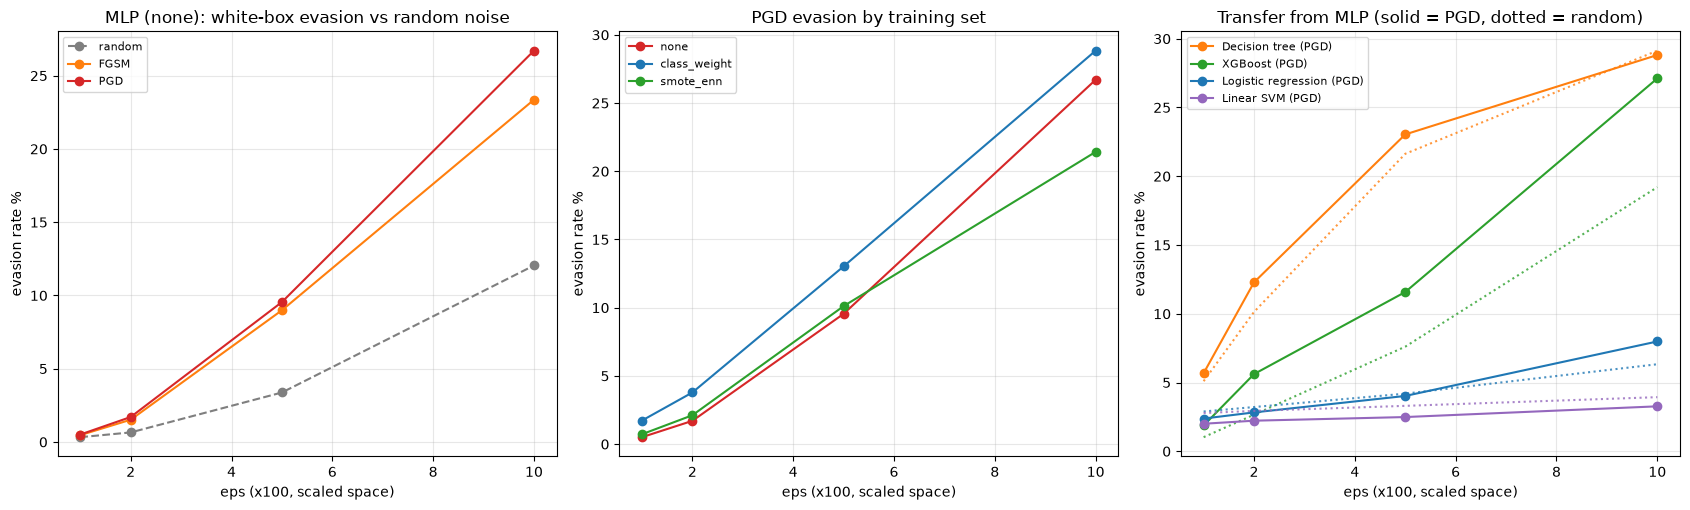

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))

d = results[results.model == "none"]
for nm, c, st in [("random", "tab:gray", "--"), ("FGSM", "tab:orange", "-"), ("PGD", "tab:red", "-")]:
    x = d[d.attack == nm]; ax[0].plot(x.eps * 100, x.evasion_rate * 100, st, marker="o", color=c, label=nm)
ax[0].set_title("MLP (none): white-box evasion vs random noise")

for s, c in [("none", "tab:red"), ("class_weight", "tab:blue"), ("smote_enn", "tab:green")]:
    x = results[(results.model == s) & (results.attack == "PGD")]
    ax[1].plot(x.eps * 100, x.evasion_rate * 100, marker="o", color=c, label=s)
ax[1].set_title("PGD evasion by training set")

for tg, c in [("Decision tree", "tab:orange"), ("XGBoost", "tab:green"),
              ("Logistic regression", "tab:blue"), ("Linear SVM", "tab:purple")]:
    x = transfer[(transfer.target == tg) & (transfer.attack == "PGD")]
    ax[2].plot(x.eps * 100, x.evasion_rate * 100, marker="o", color=c, label=tg + " (PGD)")
    x = transfer[(transfer.target == tg) & (transfer.attack == "random")]
    ax[2].plot(x.eps * 100, x.evasion_rate * 100, ":", color=c, alpha=.8)
ax[2].set_title("Transfer from MLP (solid = PGD, dotted = random)")

for a in ax:
    a.set_xlabel("eps (x100, scaled space)"); a.set_ylabel("evasion rate %"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(P / "attack_results.png", dpi=150); plt.show()